In [1]:
import networkx as nx
from genetic_algorithm_01 import genetic_algorithm_01
import numpy as np
import matplotlib.pyplot as plt

In [2]:

def draw_graph(G, genome):
    e = len(G.edges())
    pos = nx.forceatlas2_layout(G)
    colors = list(genome.values())
    nx.draw(G, pos=pos,edge_color=colors)
    edge_labels = dict(zip(G.edges(), colors))
    nx.draw_networkx_edge_labels(G,pos=pos,edge_labels=edge_labels)

def draw_generations(file):
    with open(file, "r", encoding="utf-8") as f:
        lines = f.readlines()
        y1 = []
        y2 = []
        for line in lines:
            a,b = line.strip().split(',')
            y1.append(int(a))
            y2.append(float(b))
        x = np.arange(len(lines))
    y1 = np.array(y1)
    y2 = np.array(y2)
    plt.figure(figsize = (10,10))
    plt.plot(x,y1, label = 'Maximum')
    plt.plot(x,y2, label = 'Mean')
    plt.legend()

    plt.show()

def post_procces(graph, genome: dict[frozenset[int], int]):
    zero_edges = []
    one_edges = []
    for edge, color in genome.items():
        if color == 0:
            zero_edges.append(tuple(edge))
        else:
            one_edges.append(tuple(edge))

    zero_graph = graph.edge_subgraph(zero_edges)
    one_graph = graph.edge_subgraph(one_edges)
    c1 = nx.connected_components(one_graph)
    components = 0
    one_edge_components = 0
    for c in nx.connected_components(zero_graph):
        components += 1
        if len(c) == 2:
            one_edge_components += 1
    for c in nx.connected_components(one_graph):
        components += 1
        if len(c) == 2:
            one_edge_components += 1
    return components, one_edge_components

8 38.0%


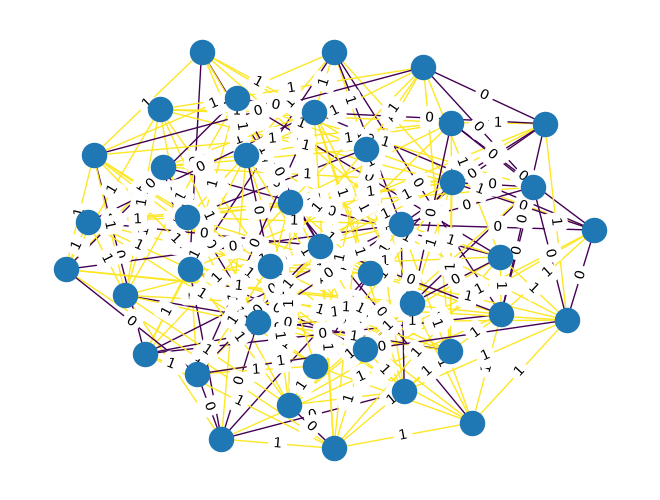

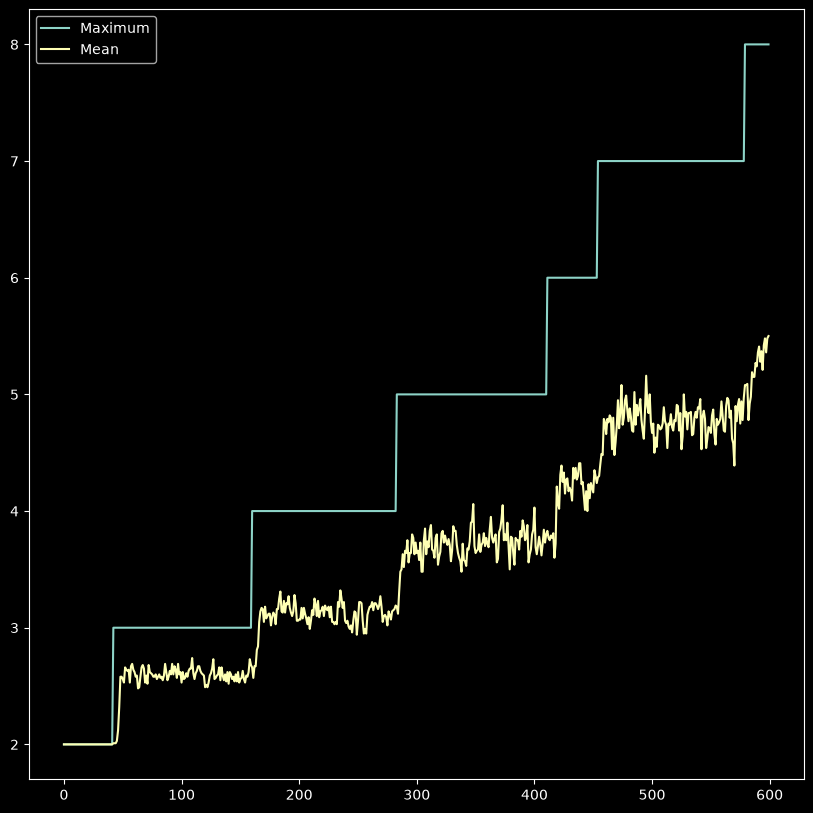

Počet farieb, počet komponentov ktoré śu jednou hranou:  (8, 6)


In [9]:
from genetic_algorithm_01 import genetic_algorithm_01
graph = nx.from_graph6_bytes(bytes(r"g????????????G?O?o?k??@[?AoOH?WI?OAGGCO_?of?F?{?YC[BHPG@c?b?aCOyKca_y_F_EeATaB@KaKCdRwN?CgF[GKEqL?wAJ{@b?aqZKKAO~`oB_?\vgcA?FesUB??", 'utf-8'))
gen = genetic_algorithm_01(graph, crossover='edge_cut', generations=600)

draw_graph(graph,gen)
draw_generations('log')
print("Počet farieb, počet komponentov ktoré śu jednou hranou: ",post_procces(graph,gen))